# Proyecto final: EDA de reservas de hotel
## Notebook 02 · Análisis descriptivo y estadístico
**Alumno:** Carlos Luque Camacho

Trabajo con el conjunto final que preparé en el notebook 01 (`data/processed/hotel_bookings_final.csv`).

Preguntas que quiero responder:
1. ¿Cómo son las reservas de cada hotel (precio, noches, cancelaciones, ingresos)?
2. ¿Qué factores están relacionados con las cancelaciones?
3. ¿Cómo cambia el precio a lo largo del año?
4. ¿De dónde vienen los clientes y influye su país en el precio que pagan?
5. ¿Influye el tiempo (temperatura, lluvia) en las reservas?

Cada conclusión la compruebo con una prueba estadística (nivel de significancia α = 0,05).

In [2]:
%pip install seaborn scipy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Si alguna librería no está instalada, ejecutar una vez: %pip install seaborn scipy
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

RUTA_PROCESSED = "../data/processed/"
RUTA_IMG = "../img/"
os.makedirs(RUTA_IMG, exist_ok=True)   # carpeta donde guardo los gráficos para el informe y el README

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
ALFA = 0.05

In [4]:
df = pd.read_csv(RUTA_PROCESSED + "hotel_bookings_final.csv",
                 parse_dates=["fecha_llegada", "fecha_salida", "fecha_estado_reserva"])

# El orden de los grupos de antelación se pierde al guardar en CSV, lo vuelvo a poner
orden_antelacion = ["0-7 días", "8-30 días", "31-90 días", "91-180 días", "Más de 180 días"]
df["grupo_antelacion"] = pd.Categorical(df["grupo_antelacion"], categories=orden_antelacion, ordered=True)

print(df.shape)
df.head()

(86637, 51)


,hotel,cancelada,antelacion_dias,anio_llegada,semana_llegada,dia_llegada,noches_fin_semana,noches_entre_semana,adultos,ninos,bebes,regimen,codigo_pais,segmento_mercado,canal_distribucion,cliente_repetidor,cancelaciones_previas,reservas_previas_no_canceladas,habitacion_reservada,habitacion_asignada,cambios_reserva,tipo_deposito,dias_lista_espera,tipo_cliente,precio_medio_noche,plazas_parking,peticiones_especiales,estado_reserva,fecha_estado_reserva,tiene_agencia,reserva_empresa,total_noches,mes_llegada,fecha_llegada,fecha_salida,total_huespedes,ingreso_reserva,ingreso_real,dia_semana_llegada,temporada,habitacion_cambiada,grupo_antelacion,pib_per_capita,pais,region_mundial,nivel_renta,temp_max,temp_min,lluvia_mm,horas_sol,dia_lluvioso
0,Resort (Algarve),0,7,2015,27,1,0,1,1,0,0,Alojamiento y desayuno,GBR,Direct,Direct,0,0,0,A,C,0,Sin depósito,0,Transient,75.0,0,0,Completada,2015-07-02,False,False,1,7,2015-07-01,2015-07-02,1,75.0,75.0,Miércoles,Verano,True,0-7 días,45256.04,United Kingdom,Europe & Central Asia,Renta alta,24.7,18.6,0.0,13.7,False
1,Resort (Algarve),0,13,2015,27,1,0,1,1,0,0,Alojamiento y desayuno,GBR,Corporate,Corporate,0,0,0,A,A,0,Sin depósito,0,Transient,75.0,0,0,Completada,2015-07-02,True,False,1,7,2015-07-01,2015-07-02,1,75.0,75.0,Miércoles,Verano,False,8-30 días,45256.04,United Kingdom,Europe & Central Asia,Renta alta,24.7,18.6,0.0,13.7,False
2,Resort (Algarve),0,14,2015,27,1,0,2,2,0,0,Alojamiento y desayuno,GBR,Online TA,TA/TO,0,0,0,A,A,0,Sin depósito,0,Transient,98.0,0,1,Completada,2015-07-03,True,False,2,7,2015-07-01,2015-07-03,2,196.0,196.0,Miércoles,Verano,False,8-30 días,45256.04,United Kingdom,Europe & Central Asia,Renta alta,24.7,18.6,0.0,13.7,False
3,Resort (Algarve),0,0,2015,27,1,0,2,2,0,0,Alojamiento y desayuno,PRT,Direct,Direct,0,0,0,C,C,0,Sin depósito,0,Transient,107.0,0,0,Completada,2015-07-03,False,False,2,7,2015-07-01,2015-07-03,2,214.0,214.0,Miércoles,Verano,False,0-7 días,19215.78,Portugal,Europe & Central Asia,Renta alta,24.7,18.6,0.0,13.7,False
4,Resort (Algarve),0,9,2015,27,1,0,2,2,0,0,Pensión completa,PRT,Direct,Direct,0,0,0,C,C,0,Sin depósito,0,Transient,103.0,0,1,Completada,2015-07-03,True,False,2,7,2015-07-01,2015-07-03,2,206.0,206.0,Miércoles,Verano,False,8-30 días,19215.78,Portugal,Europe & Central Asia,Renta alta,24.7,18.6,0.0,13.7,False


## 1. Análisis descriptivo

### 1.1 KPIs generales

In [5]:
total_reservas = len(df)
tasa_cancelacion = df["cancelada"].mean() * 100
precio_medio = df["precio_medio_noche"].mean()
noches_medias = df["total_noches"].mean()
ingresos_reales = df["ingreso_real"].sum()

print(f"Total de reservas:        {total_reservas:,}")
print(f"Tasa de cancelación:      {tasa_cancelacion:.1f} %")
print(f"Precio medio por noche:   {precio_medio:.2f} €")
print(f"Noches medias por reserva:{noches_medias:.2f}")
print(f"Ingresos reales (no canceladas): {ingresos_reales:,.0f} €")

Total de reservas:        86,637
Tasa de cancelación:      27.7 %
Precio medio por noche:   107.18 €
Noches medias por reserva:3.65
Ingresos reales (no canceladas): 22,967,612 €


### 1.2 Estadísticos de las variables numéricas principales

In [6]:
numericas = ["antelacion_dias", "total_noches", "total_huespedes", "precio_medio_noche",
             "ingreso_reserva", "peticiones_especiales", "pib_per_capita", "temp_max", "lluvia_mm"]
df[numericas].describe().round(2)

,antelacion_dias,total_noches,total_huespedes,precio_medio_noche,ingreso_reserva,peticiones_especiales,pib_per_capita,temp_max,lluvia_mm
count,86637.00,86637.00,86637.00,86637.00,86637.00,86637.00,86118.00,86637.00,86637.00
mean,80.29,3.65,2.03,107.18,397.59,0.70,32544.82,21.91,1.32
std,86.07,2.74,0.79,51.31,368.87,0.83,16921.71,5.59,4.27
min,0.00,1.00,1.00,0.00,0.00,0.00,232.94,9.60,0.00
25%,12.00,2.00,2.00,72.90,157.00,0.00,19980.28,16.90,0.00
50%,50.00,3.00,2.00,99.00,300.00,0.00,28381.34,21.60,0.00
75%,126.00,5.00,2.00,134.43,504.00,1.00,41258.54,26.20,0.10
max,709.00,69.00,55.00,510.00,7590.00,5.00,173604.67,39.10,67.70


In [7]:
# Asimetría y curtosis: me dicen si las variables se parecen a una distribución normal
pd.DataFrame({
    "asimetria": df[numericas].skew(),
    "curtosis": df[numericas].kurtosis(),
}).round(2)

,asimetria,curtosis
antelacion_dias,1.42,2.08
total_noches,2.98,24.04
total_huespedes,10.58,528.68
precio_medio_noche,0.93,1.58
ingreso_reserva,2.70,14.08
peticiones_especiales,1.08,0.82
pib_per_capita,1.01,1.83
temp_max,0.24,-0.84
lluvia_mm,5.33,40.77


Casi todas las variables tienen **asimetría positiva** (cola larga a la derecha): la mayoría de reservas son de pocas noches,
poca antelación y precio medio, y unas pocas tienen valores muy altos. No son distribuciones normales.

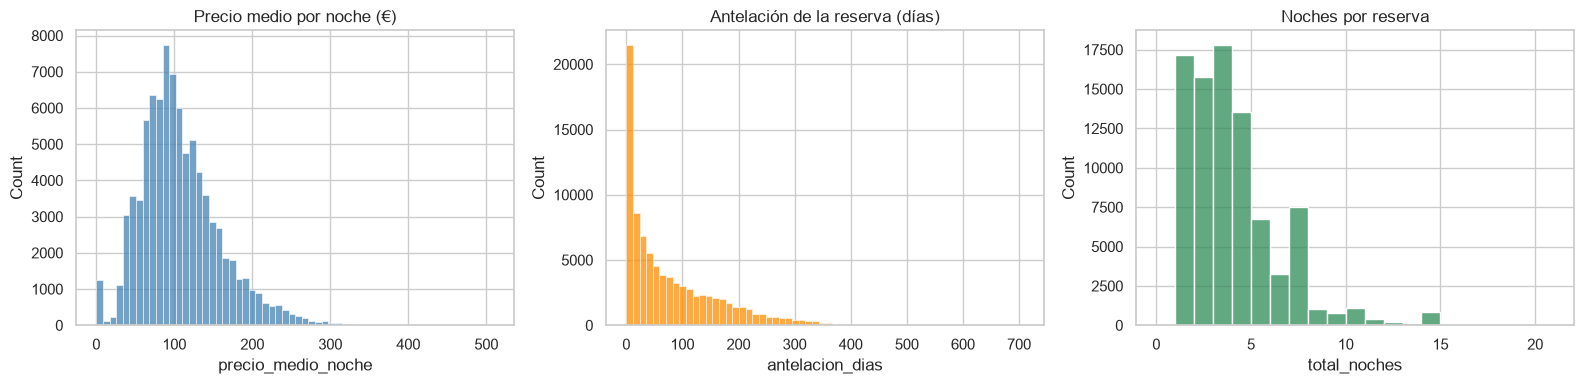

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["precio_medio_noche"], bins=60, ax=axes[0], color="steelblue")
axes[0].set_title("Precio medio por noche (€)")
sns.histplot(df["antelacion_dias"], bins=60, ax=axes[1], color="darkorange")
axes[1].set_title("Antelación de la reserva (días)")
sns.histplot(df["total_noches"], bins=range(0, 22), ax=axes[2], color="seagreen")
axes[2].set_title("Noches por reserva")
plt.tight_layout()
plt.savefig(RUTA_IMG + "01_distribuciones.png", dpi=120)
plt.show()

### 1.3 Comparación entre los dos hoteles

In [9]:
resumen_hotel = df.groupby("hotel").agg(
    reservas=("cancelada", "size"),
    tasa_cancelacion=("cancelada", "mean"),
    precio_medio=("precio_medio_noche", "mean"),
    noches_medias=("total_noches", "mean"),
    huespedes_medios=("total_huespedes", "mean"),
    ingresos_reales=("ingreso_real", "sum"),
)
resumen_hotel["tasa_cancelacion"] = (resumen_hotel["tasa_cancelacion"] * 100).round(1)
resumen_hotel.round(2)

,reservas,tasa_cancelacion,precio_medio,noches_medias,huespedes_medios,ingresos_reales
hotel,,,,,,
Hotel ciudad (Lisboa),53042,30.2,111.66,3.16,2.02,12150577.73
Resort (Algarve),33595,23.7,100.12,4.44,2.04,10817034.22


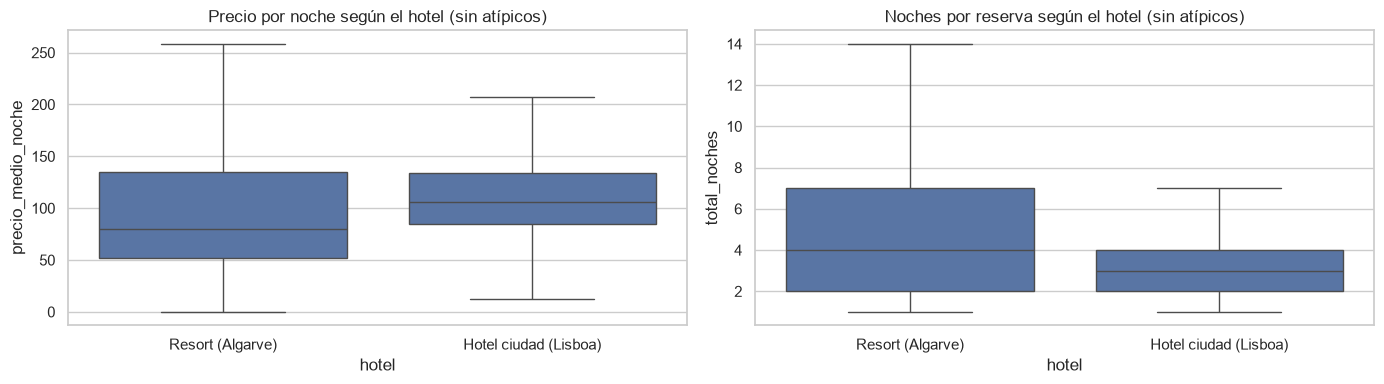

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df, x="hotel", y="precio_medio_noche", ax=axes[0], showfliers=False)
axes[0].set_title("Precio por noche según el hotel (sin atípicos)")
sns.boxplot(data=df, x="hotel", y="total_noches", ax=axes[1], showfliers=False)
axes[1].set_title("Noches por reserva según el hotel (sin atípicos)")
plt.tight_layout()
plt.savefig(RUTA_IMG + "02_hoteles.png", dpi=120)
plt.show()

### 1.4 Evolución en el tiempo

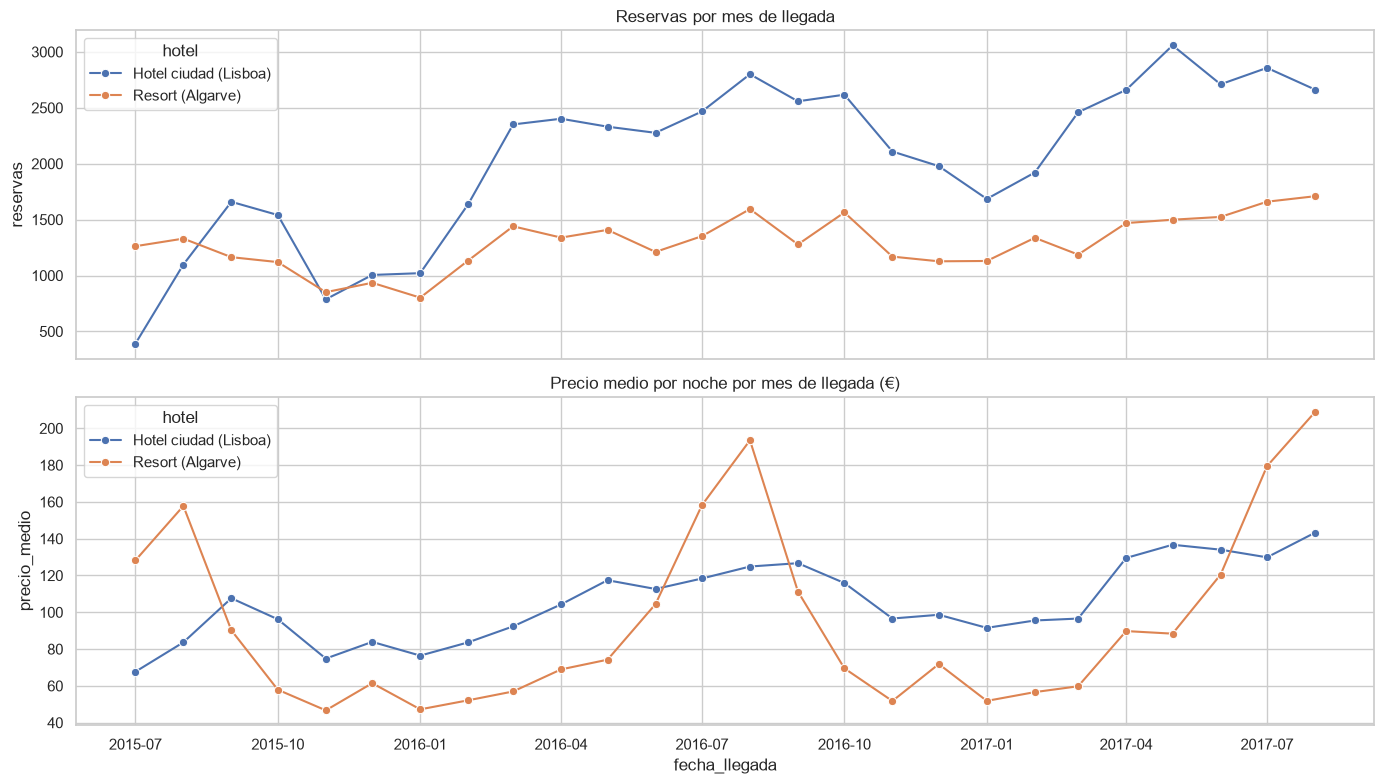

In [11]:
# Reservas y precio medio por mes y hotel
mensual = df.groupby([pd.Grouper(key="fecha_llegada", freq="MS"), "hotel"]).agg(
    reservas=("cancelada", "size"),
    precio_medio=("precio_medio_noche", "mean"),
).reset_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
sns.lineplot(data=mensual, x="fecha_llegada", y="reservas", hue="hotel", marker="o", ax=axes[0])
axes[0].set_title("Reservas por mes de llegada")
sns.lineplot(data=mensual, x="fecha_llegada", y="precio_medio", hue="hotel", marker="o", ax=axes[1])
axes[1].set_title("Precio medio por noche por mes de llegada (€)")
plt.tight_layout()
plt.savefig(RUTA_IMG + "03_evolucion_mensual.png", dpi=120)
plt.show()

In [12]:
# Precio medio por temporada y hotel
pd.pivot_table(df, values="precio_medio_noche", index="temporada", columns="hotel", aggfunc="mean").round(2)

hotel,Hotel ciudad (Lisboa),Resort (Algarve)
temporada,,
Invierno,89.99,57.19
Otoño,107.96,72.91
Primavera,114.10,73.62
Verano,123.52,159.66


### 1.5 Origen de los clientes

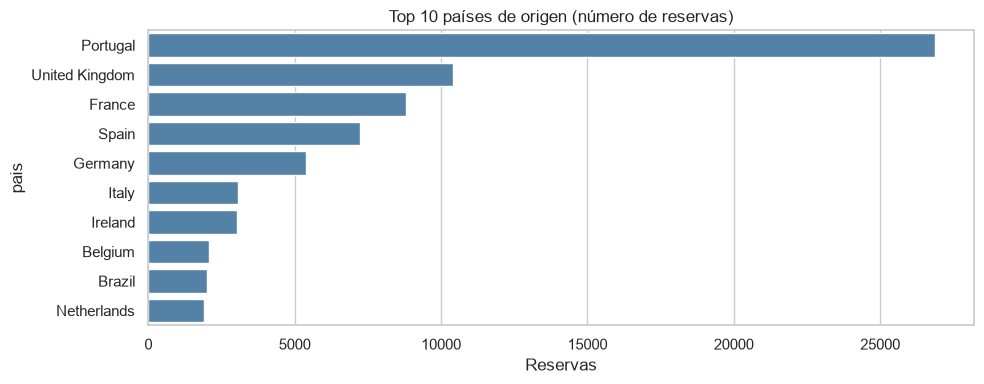

In [13]:
top_paises = df["pais"].value_counts().head(10)
plt.figure(figsize=(10, 4))
sns.barplot(x=top_paises.values, y=top_paises.index, color="steelblue")
plt.title("Top 10 países de origen (número de reservas)")
plt.xlabel("Reservas")
plt.tight_layout()
plt.savefig(RUTA_IMG + "04_top_paises.png", dpi=120)
plt.show()

In [14]:
# Peso de cada nivel de renta y precio medio que pagan
df.groupby("nivel_renta").agg(reservas=("cancelada", "size"),
                              precio_medio=("precio_medio_noche", "mean")).round(2)

,reservas,precio_medio
nivel_renta,,
Desconocido,503,70.90
Renta alta,79841,106.78
Renta baja,87,105.72
Renta media-alta,5243,113.86
Renta media-baja,963,123.42


### 1.6 Cancelaciones

In [15]:
# Tasa de cancelación (%) según distintas variables
for columna in ["grupo_antelacion", "tipo_deposito", "segmento_mercado", "cliente_repetidor", "peticiones_especiales"]:
    tabla = df.groupby(columna, observed=True)["cancelada"].agg(["size", "mean"])
    tabla["mean"] = (tabla["mean"] * 100).round(1)
    print(tabla.rename(columns={"size": "reservas", "mean": "% cancelación"}), "\n")

                  reservas  % cancelación
grupo_antelacion                         
0-7 días             17855            8.5
8-30 días            16234           25.5
31-90 días           22633           32.1
91-180 días          18190           35.1
Más de 180 días      11725           39.8 

                 reservas  % cancelación
tipo_deposito                           
No reembolsable      1037           94.7
Reembolsable          107           24.3
Sin depósito        85493           26.9 

                  reservas  % cancelación
segmento_mercado                         
Aviation               222           19.8
Complementary          682           12.2
Corporate             4155           12.2
Direct               11652           14.9
Groups                4891           27.2
Offline TA/TO        13748           14.9
Online TA            51285           35.5
Undefined                2          100.0 

                   reservas  % cancelación
cliente_repetidor               

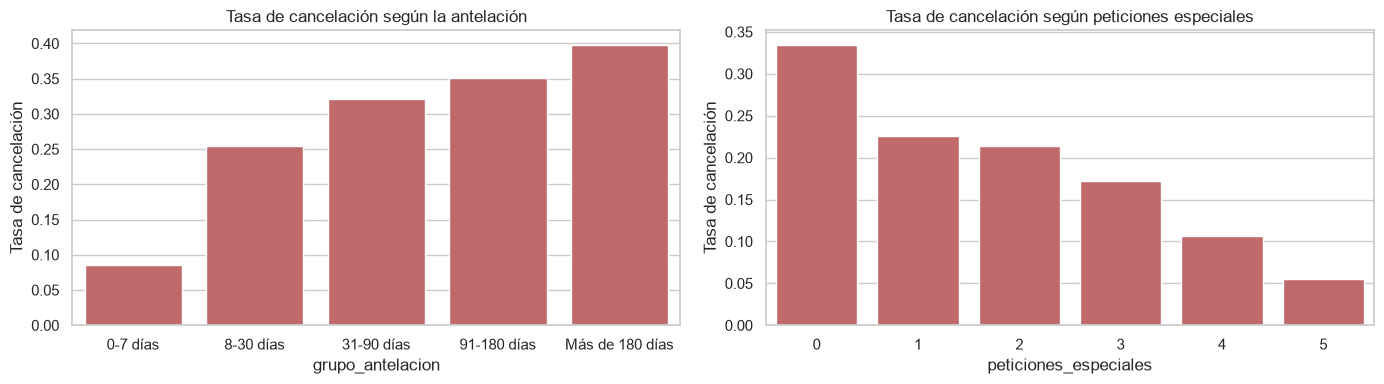

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=df, x="grupo_antelacion", y="cancelada", ax=axes[0], color="indianred", errorbar=None)
axes[0].set_title("Tasa de cancelación según la antelación")
axes[0].set_ylabel("Tasa de cancelación")
sns.barplot(data=df, x="peticiones_especiales", y="cancelada", ax=axes[1], color="indianred", errorbar=None)
axes[1].set_title("Tasa de cancelación según peticiones especiales")
axes[1].set_ylabel("Tasa de cancelación")
plt.tight_layout()
plt.savefig(RUTA_IMG + "05_cancelaciones.png", dpi=120)
plt.show()

### 1.7 Correlaciones entre variables numéricas

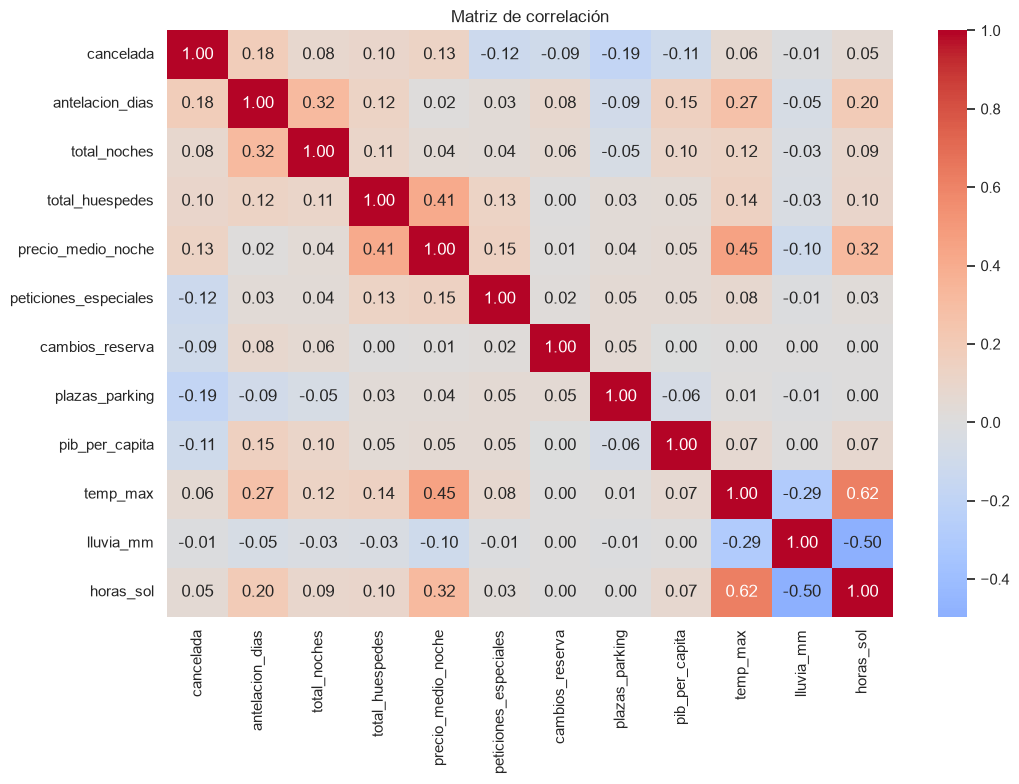

In [17]:
columnas_corr = ["cancelada", "antelacion_dias", "total_noches", "total_huespedes", "precio_medio_noche",
                 "peticiones_especiales", "cambios_reserva", "plazas_parking", "pib_per_capita",
                 "temp_max", "lluvia_mm", "horas_sol"]
correlaciones = df[columnas_corr].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.savefig(RUTA_IMG + "06_correlaciones.png", dpi=120)
plt.show()

## 2. Análisis estadístico

### 2.1 ¿El precio por noche sigue una distribución normal?
- H₀: el precio sigue una distribución normal.
- H₁: no la sigue.

Shapiro-Wilk solo admite hasta 5.000 datos, así que uso una muestra aleatoria.

In [18]:
muestra = df["precio_medio_noche"].sample(5000, random_state=42)
estadistico, p_valor = stats.shapiro(muestra)
print(f"Shapiro-Wilk: estadístico = {estadistico:.4f}, p-valor = {p_valor:.2e}")
print("Rechazo H₀: el precio NO es normal" if p_valor < ALFA else "No rechazo H₀")

Shapiro-Wilk: estadístico = 0.9514, p-valor = 7.81e-38
Rechazo H₀: el precio NO es normal


Como el precio no es normal, en las comparaciones uso además pruebas **no paramétricas** (Mann-Whitney y Kruskal-Wallis),
que no exigen normalidad. Con tantos datos, las pruebas t y ANOVA también son fiables (teorema central del límite).

### 2.2 Intervalo de confianza del precio medio por noche (95 %)

In [19]:
precio = df["precio_medio_noche"]
ic = stats.t.interval(0.95, len(precio) - 1, loc=precio.mean(), scale=stats.sem(precio))
print(f"Precio medio: {precio.mean():.2f} € · IC 95 %: [{ic[0]:.2f} €, {ic[1]:.2f} €]")

Precio medio: 107.18 € · IC 95 %: [106.84 €, 107.53 €]


### 2.3 ¿El precio por noche es distinto en el hotel de ciudad y en el resort?
- H₀: el precio medio es igual en los dos hoteles.
- H₁: es distinto.

In [20]:
precio_ciudad = df[df["hotel"] == "Hotel ciudad (Lisboa)"]["precio_medio_noche"]
precio_resort = df[df["hotel"] == "Resort (Algarve)"]["precio_medio_noche"]

# equal_var=False porque las varianzas de los dos grupos no tienen por qué ser iguales (prueba t de Welch)
t, p_t = stats.ttest_ind(precio_ciudad, precio_resort, equal_var=False)
u, p_u = stats.mannwhitneyu(precio_ciudad, precio_resort)
print(f"Media ciudad: {precio_ciudad.mean():.2f} € · Media resort: {precio_resort.mean():.2f} €")
print(f"Prueba t:      t = {t:.2f}, p-valor = {p_t:.2e}")
print(f"Mann-Whitney:  p-valor = {p_u:.2e}")
print("Rechazo H₀: el precio es distinto entre hoteles" if p_t < ALFA else "No rechazo H₀")

Media ciudad: 111.66 € · Media resort: 100.12 €
Prueba t:      t = 29.64, p-valor = 1.93e-191
Mann-Whitney:  p-valor = 0.00e+00
Rechazo H₀: el precio es distinto entre hoteles


### 2.4 ¿El precio cambia según la temporada?
- H₀: el precio medio es igual en las cuatro temporadas.
- H₁: al menos una temporada tiene un precio distinto.

In [21]:
grupos = [grupo["precio_medio_noche"] for _, grupo in df.groupby("temporada")]
f, p_f = stats.f_oneway(*grupos)
h, p_h = stats.kruskal(*grupos)
print(df.groupby("temporada")["precio_medio_noche"].mean().round(2))
print(f"ANOVA:          F = {f:.1f}, p-valor = {p_f:.2e}")
print(f"Kruskal-Wallis: p-valor = {p_h:.2e}")
print("Rechazo H₀: el precio depende de la temporada" if p_f < ALFA else "No rechazo H₀")

temporada
Invierno      76.50
Otoño         94.36
Primavera     99.80
Verano       138.08
Name: precio_medio_noche, dtype: float64
ANOVA:          F = 7436.2, p-valor = 0.00e+00
Kruskal-Wallis: p-valor = 0.00e+00
Rechazo H₀: el precio depende de la temporada


### 2.5 ¿La cancelación depende del hotel?
Prueba chi-cuadrado (dos variables categóricas).
- H₀: cancelar y el tipo de hotel son independientes.
- H₁: están relacionados.

In [22]:
tabla_hotel = pd.crosstab(df["hotel"], df["cancelada"])
chi2, p_chi, gl, esperadas = stats.chi2_contingency(tabla_hotel)
print(tabla_hotel)
print(f"Chi-cuadrado = {chi2:.1f}, p-valor = {p_chi:.2e}")
print("Rechazo H₀: la cancelación depende del hotel" if p_chi < ALFA else "No rechazo H₀")

cancelada                  0      1
hotel                              
Hotel ciudad (Lisboa)  37021  16021
Resort (Algarve)       25631   7964
Chi-cuadrado = 433.5, p-valor = 2.77e-96
Rechazo H₀: la cancelación depende del hotel


### 2.6 ¿La cancelación depende del tipo de depósito?
- H₀: cancelar y el tipo de depósito son independientes.
- H₁: están relacionados.

In [23]:
tabla_deposito = pd.crosstab(df["tipo_deposito"], df["cancelada"])
chi2, p_chi, gl, esperadas = stats.chi2_contingency(tabla_deposito)
print(tabla_deposito)
print(f"Chi-cuadrado = {chi2:.1f}, p-valor = {p_chi:.2e}")
print("Rechazo H₀: la cancelación depende del depósito" if p_chi < ALFA else "No rechazo H₀")

cancelada            0      1
tipo_deposito                
No reembolsable     55    982
Reembolsable        81     26
Sin depósito     62516  22977
Chi-cuadrado = 2354.6, p-valor = 0.00e+00
Rechazo H₀: la cancelación depende del depósito


### 2.7 ¿Las reservas que se cancelan se hacen con más antelación?
- H₀: la antelación media es igual en reservas canceladas y no canceladas.
- H₁: es distinta.

In [24]:
antelacion_cancel = df[df["cancelada"] == 1]["antelacion_dias"]
antelacion_no_cancel = df[df["cancelada"] == 0]["antelacion_dias"]
t, p_t = stats.ttest_ind(antelacion_cancel, antelacion_no_cancel, equal_var=False)
print(f"Antelación media canceladas: {antelacion_cancel.mean():.1f} días")
print(f"Antelación media no canceladas: {antelacion_no_cancel.mean():.1f} días")
print(f"Prueba t: t = {t:.2f}, p-valor = {p_t:.2e}")
print("Rechazo H₀: las canceladas se reservan con más antelación" if p_t < ALFA else "No rechazo H₀")

Antelación media canceladas: 105.8 días
Antelación media no canceladas: 70.5 días
Prueba t: t = 52.15, p-valor = 0.00e+00
Rechazo H₀: las canceladas se reservan con más antelación


### 2.8 ¿El precio depende del nivel de renta del país del cliente? (Banco Mundial)
- H₀: el precio medio es igual para todos los niveles de renta.
- H₁: al menos un nivel paga un precio distinto.

In [25]:
con_renta = df[df["nivel_renta"] != "Desconocido"]
grupos_renta = [grupo["precio_medio_noche"] for _, grupo in con_renta.groupby("nivel_renta")]
h, p_h = stats.kruskal(*grupos_renta)
print(con_renta.groupby("nivel_renta")["precio_medio_noche"].agg(["size", "mean"]).round(2))
print(f"Kruskal-Wallis: p-valor = {p_h:.2e}")

# Correlación entre el PIB per cápita del país y el precio pagado
con_pib = df.dropna(subset=["pib_per_capita"])
r, p_r = stats.pearsonr(con_pib["pib_per_capita"], con_pib["precio_medio_noche"])
print(f"Correlación PIB per cápita - precio: r = {r:.3f}, p-valor = {p_r:.2e}")

                   size    mean
nivel_renta                    
Renta alta        79841  106.78
Renta baja           87  105.72
Renta media-alta   5243  113.86
Renta media-baja    963  123.42
Kruskal-Wallis: p-valor = 1.10e-54
Correlación PIB per cápita - precio: r = 0.052, p-valor = 1.09e-52


### 2.9 ¿Influye el tiempo? (Open-Meteo)
**a)** Relación entre la temperatura máxima del día de llegada y el precio en el resort.

Resort · correlación temperatura máxima - precio: r = 0.673, p-valor = 0.00e+00


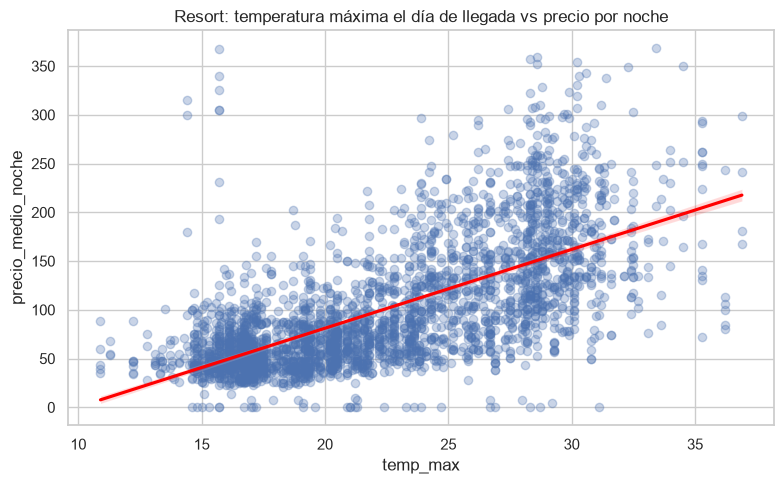

In [26]:
resort = df[df["hotel"] == "Resort (Algarve)"]
r, p_r = stats.pearsonr(resort["temp_max"], resort["precio_medio_noche"])
print(f"Resort · correlación temperatura máxima - precio: r = {r:.3f}, p-valor = {p_r:.2e}")

plt.figure(figsize=(8, 5))
sns.regplot(data=resort.sample(3000, random_state=42), x="temp_max", y="precio_medio_noche",
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.title("Resort: temperatura máxima el día de llegada vs precio por noche")
plt.tight_layout()
plt.savefig(RUTA_IMG + "07_temperatura_precio.png", dpi=120)
plt.show()

**b)** ¿Se cancela distinto cuando llueve el día de llegada?
- H₀: la tasa de cancelación es igual en días con y sin lluvia.
- H₁: es distinta.

In [27]:
tabla_lluvia = pd.crosstab(df["dia_lluvioso"], df["cancelada"])
chi2, p_chi, gl, esperadas = stats.chi2_contingency(tabla_lluvia)
print(df.groupby("dia_lluvioso")["cancelada"].mean().mul(100).round(1))
print(f"Chi-cuadrado = {chi2:.1f}, p-valor = {p_chi:.2e}")

dia_lluvioso
False    27.9
True     26.3
Name: cancelada, dtype: float64
Chi-cuadrado = 15.1, p-valor = 1.02e-04


## 3. Conclusiones

**Descriptivo**
- Tras la limpieza quedan **86.637 reservas**, con una tasa de cancelación del **27,7 %**.
- El hotel de ciudad tiene más reservas (53.042), más caras (111,66 €/noche) y más cortas (3,2 noches) que el resort que tiene estancias más largas (4,4 noches) a un precio algo menor (100,12 €).
- El precio depende mucho de la temporada: en verano se paga de media 138 €/noche y en invierno 76 €.
- Los clientes vienen sobre todo de UK y la europa occidental (Portugal, Reino Unido, Francia, España y Alemania), y el 92 % de las reservas son de países de renta alta.

**Estadístico** (todas las pruebas con α = 0,05)
- Como el precio no sigue una distribución normal, además de la prueba t y ANOVA he usado sus equivalentes que no necesitan normalidad (Mann-Whitney y Kruskal-Wallis). Ambas llegan a la misma conclusión.
- El precio medio por noche está entre 106,84 € y 107,53 € con un 95 % de confianza.
- El precio es significativamente distinto entre hoteles y entre temporadas.
- La cancelación depende del hotel (30,2 % en ciudad frente a 23,7 % en el resort) y, sobre todo, del depósito: casi el 95 % de las reservas *no reembolsables* acaban canceladas, algo que habría que revisar con el hotel (puede tratarse de reservas de grupos o agencias).
- Las reservas canceladas se hacen con más antelación: con menos de una semana solo se cancela el 8,5 %, y con más de 180 días casi el 40 %.
- Los clientes repetidores (8,2 %) y quienes hacen peticiones especiales cancelan mucho menos.
- El nivel de renta del país apenas influye en el precio: las diferencias son estadísticamente significativas por el gran tamaño de la muestra, pero pequeñas en la práctica.
- En el resort, la temperatura del día de llegada tiene una correlación alta con el precio (r ≈ 0,67), pero no es causa directa: los días calurosos son de verano, que es cuando el precio sube.
- La lluvia el día de llegada cambia muy poco la tasa de cancelación (26,3 % frente a 27,9 %). La diferencia sale significativa por la cantidad de datos, pero es pequeña en la práctica. Tiene sentido: la mayoría de clientes cancelan días o semanas antes y no saben qué tiempo hará.